[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/matveyyaros/Project-activities-case-9/blob/ruslan/notebooks/03_features_preprocessing.ipynb)

# 🧪 **Новые признаки, стратегия предобработки и масштабирование**

Продолжение тетрадки `EDA_wildblueberry.ipynb`. Там изучены данные, найдены аномалии и ловушки. Здесь — три следующих шага:

1. **Постановка задачи** — коротко, чтобы тетрадка читалась отдельно.
2. **Новые признаки:** выдвигаем гипотезы по выводам EDA, создаём признаки и проверяем, помогают ли они.
3. **Стратегия предобработки:** пропуски, кодирование, масштабирование — что и почему будем делать.
4. **Сравнение способов масштабирования** на одной схеме валидации: метрика и коэффициенты.

## 📚 Импорты и данные

In [1]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")  # шум от индикатора загрузки kagglehub

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

try:
    import kagglehub
except ImportError:  # в Colab kagglehub может не быть
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
    import kagglehub

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

In [2]:
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

KAGGLE_DATASET = "saurabhshahane/wild-blueberry-yield-prediction"
CSV_NAME = "WildBlueberryPollinationSimulationData.csv"
DATA_PATH = ROOT / "data" / "raw" / CSV_NAME
DATA_URL = ("https://raw.githubusercontent.com/matveyyaros/Project-activities-case-9/"
            "506b161/data/raw/WildBlueberryPollinationSimulationData.csv")

try:
    kaggle_dir = Path(kagglehub.dataset_download(KAGGLE_DATASET))
    df = pd.read_csv(next(kaggle_dir.rglob(CSV_NAME)))
    print(f"🌐 Данные скачаны с Kaggle: {KAGGLE_DATASET}")
except Exception as e:
    print(f"⚠️ Kaggle недоступен ({type(e).__name__}: {e})")
    df = pd.read_csv(DATA_PATH) if DATA_PATH.exists() else pd.read_csv(DATA_URL)
    print("📂 Данные загружены из запасного источника")

# Решения из EDA: основная сетка эксперимента, без Row#, по одному представителю температур и дождей
df_clean = df[df["clonesize"].isin([12.5, 25, 37.5])].drop(columns="Row#").reset_index(drop=True)
FACTORS = ["clonesize", "honeybee", "bumbles", "andrena", "osmia", "AverageOfUpperTRange", "RainingDays"]
TARGET = "yield"
y = df_clean[TARGET]
print(f"Строк: {len(df_clean)}, исходных факторов: {len(FACTORS)}")

🌐 Данные скачаны с Kaggle: saurabhshahane/wild-blueberry-yield-prediction
Строк: 759, исходных факторов: 7


---
# **1. Постановка задачи** 🎯

| Вопрос | Ответ |
|---|---|
| **Что предсказываем** | `yield` — урожай черники с поля |
| **Тип задачи** | **регрессия**: целевая переменная — непрерывное число |
| **Один объект** | одна строка = **один сценарий** компьютерной модели опыления: комбинация размера клона, плотности четырёх видов пчёл, температуры и дождей. Значение — среднее по 100 прогонам симуляции |
| **Признаки** | 7 факторов, известных до сезона (выбраны в EDA, разделы 3.4–3.5) |
| **Чем меряем** | MAE — средняя ошибка в единицах урожая; R² — доля объяснённого разброса |

**Схема валидации — одна на всю тетрадку:** 5-кратная кросс-валидация с перемешиванием и **стратификацией по `clonesize`** (клон 37.5 редкий — 25 строк, он должен попадать в каждую часть). Все сравнения ниже сделаны на одних и тех же разбиениях, поэтому разница в метриках — это разница подходов, а не случайность разбиения.

In [3]:
CV = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
          .split(df_clean, df_clean["clonesize"].astype(str)))

def evaluate(model, cols, data=df_clean):
    """MAE и R² на общей схеме валидации."""
    res = cross_validate(model, data[cols], y, cv=CV,
                         scoring={"MAE": "neg_mean_absolute_error", "R2": "r2"})
    return {"MAE": -res["test_MAE"].mean(), "R²": res["test_R2"].mean()}

base = evaluate(LinearRegression(), FACTORS)
print(f"Точка отсчёта — линейная регрессия на 7 факторах: MAE = {base['MAE']:.0f}, R² = {base['R²']:.3f}")

Точка отсчёта — линейная регрессия на 7 факторах: MAE = 506, R² = 0.790


**Почему проверяем признаки на линейной регрессии.** Она видит только прямые зависимости. Если новый признак описывает нелинейность, линейная модель сразу станет точнее — эффект признака виден без помех. Деревья проверим в конце раздела отдельно.

---
# **2. Новые признаки: гипотезы и проверка** 🔬

Каждая гипотеза опирается на вывод EDA. Для каждой: (1) смотрим на данные, (2) создаём признак, (3) проверяем, уменьшает ли он ошибку на общей схеме валидации.

## 2.1 Гипотеза 1. У температуры есть оптимум

**Откуда:** в EDA (раздел 6.1) лучший урожай — при умеренной температуре, а и холоднее, и жарче — хуже. Пирсон у температуры всего −0.18: связь есть, но не прямая, и линейная мера её почти не видит.
**Признак:** `temp_sq` — квадрат температуры. Вместе с самой температурой он даёт параболу, и линейная модель сама найдёт положение оптимума. Мы не подставляем «оптимум 64.7» вручную: он найден на этих же данных, и это была бы подгонка под ответ.

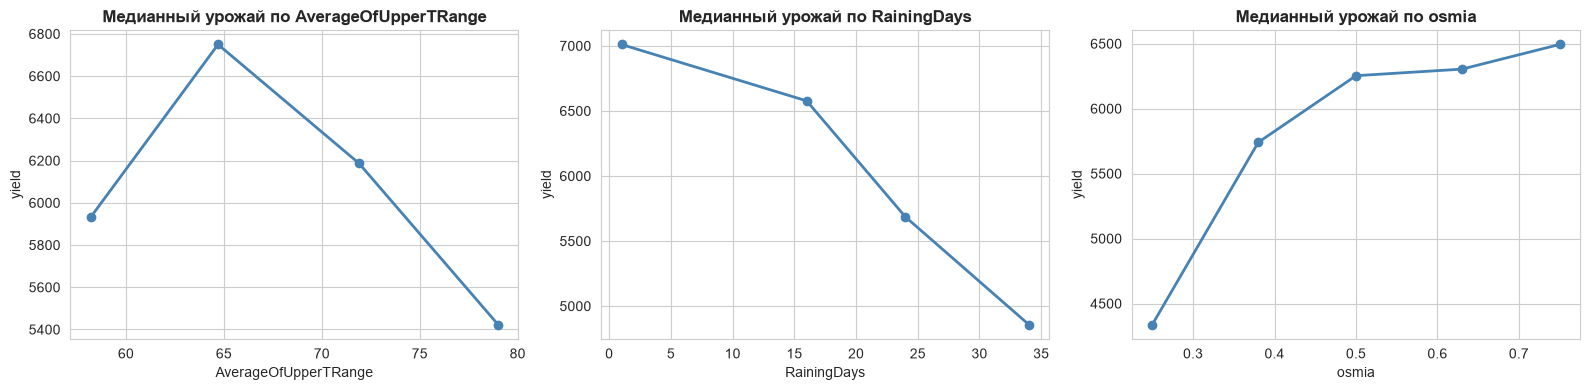

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["AverageOfUpperTRange", "RainingDays", "osmia"]):
    med = df_clean.groupby(col)[TARGET].median()
    ax.plot(med.index, med.values, "o-", color="steelblue", linewidth=2)
    ax.set_title(f"Медианный урожай по {col}", fontsize=12, fontweight="bold")
    ax.set_xlabel(col); ax.set_ylabel("yield")
plt.tight_layout()
plt.show()

- **Температура:** горб с вершиной около 65 °F — оптимум виден.
- **Дожди:** урожай падает, и **чем дождливее, тем быстрее**: от 1 до 16 дней теряется около 30 за каждый дождливый день, а после 16 дней — 80–110 за день. Это основа гипотезы 2.
- **Осмии:** быстрый рост до 0.5, дальше почти плато — основа гипотезы 4.

## 2.2 Гипотеза 2. Вред от дождей нарастает

**Признак:** `rain_sq` — квадрат числа дождливых дней. Позволяет линейной модели описать падение, которое ускоряется.

## 2.3 Гипотеза 3. Дождь в жару вредит сильнее

**Откуда:** тепловая карта «дожди × температура» в EDA (раздел 6.1). Проверим, одинаков ли вред от дождей при разной температуре.
**Признак:** `rain_x_temp` — произведение дождливых дней на температуру (взаимодействие).

In [5]:
pivot = df_clean.pivot_table(index="RainingDays", columns="AverageOfUpperTRange", values=TARGET, aggfunc="median")
drop = (pivot.loc[1] - pivot.loc[34]).rename("Потеря урожая от 1 до 34 дождливых дней")
display(pivot.round(0))
display(drop.round(0).to_frame().T)

AverageOfUpperTRange,58.2,64.7,71.9,79.0
RainingDays,,,,
1.0,6607.0,7568.0,7411.0,6823.0
16.0,6335.0,6975.0,6708.0,6329.0
24.0,6061.0,6443.0,5853.0,4582.0
34.0,4867.0,5943.0,4809.0,3777.0


AverageOfUpperTRange,58.2,64.7,71.9,79.0
Потеря урожая от 1 до 34 дождливых дней,1740.0,1625.0,2603.0,3046.0


При 64.7 °F дожди отнимают около 1600, а при 79 °F — около 3000, почти вдвое больше. Эффект дождя **зависит от температуры** — это и есть взаимодействие, которое линейная модель без нового признака не увидит.

## 2.4 Гипотеза 4. У осмий и андрен есть насыщение

**Признаки:** `osmia_sq`, `andrena_sq` — квадраты плотности: с ними линейная модель может описать замедление роста.

## 2.5 Гипотеза 5. Важна общая плотность опылителей

**Признаки:** `wild_bees` = шмели + андрены + осмии; `bees_per_clone` — все пчёлы на м² клона. Идея: урожай зависит от того, сколько опылителей приходится на растение.

In [6]:
fe = df_clean.copy()
fe["temp_sq"] = fe["AverageOfUpperTRange"] ** 2
fe["rain_sq"] = fe["RainingDays"] ** 2
fe["rain_x_temp"] = fe["RainingDays"] * fe["AverageOfUpperTRange"]
fe["osmia_sq"] = fe["osmia"] ** 2
fe["andrena_sq"] = fe["andrena"] ** 2
fe["wild_bees"] = fe["bumbles"] + fe["andrena"] + fe["osmia"]
fe["bees_per_clone"] = (fe["wild_bees"] + fe["honeybee"]) / fe["clonesize"]

CANDIDATES = {
    "temp_sq": "Г1: оптимум температуры",
    "rain_sq": "Г2: вред дождей нарастает",
    "rain_x_temp": "Г3: дождь в жару хуже",
    "osmia_sq": "Г4: насыщение осмий",
    "andrena_sq": "Г4: насыщение андрен",
    "wild_bees": "Г5: сумма диких пчёл",
    "bees_per_clone": "Г5: пчёлы на м² клона",
}

rows = []
for feat, hyp in CANDIDATES.items():
    score = evaluate(LinearRegression(), FACTORS + [feat], data=fe)
    rows.append({"признак": feat, "гипотеза": hyp,
                 "Спирмен с yield": fe[feat].corr(y, method="spearman"),
                 "MAE (7 факторов + признак)": score["MAE"],
                 "ΔMAE": score["MAE"] - base["MAE"],
                 "R²": score["R²"]})
hyp_table = pd.DataFrame(rows).set_index("признак")
print(f"Без новых признаков: MAE = {base['MAE']:.0f}, R² = {base['R²']:.3f}")
hyp_table.round(3)

Без новых признаков: MAE = 506, R² = 0.790


,гипотеза,Спирмен с yield,MAE (7 факторов + признак),ΔMAE,R²
признак,,,,,
temp_sq,Г1: оптимум температуры,-0.148,388.898,-116.619,0.871
rain_sq,Г2: вред дождей нарастает,-0.605,470.351,-35.165,0.810
rain_x_temp,Г3: дождь в жару хуже,-0.621,478.817,-26.699,0.822
osmia_sq,Г4: насыщение осмий,0.294,505.955,0.438,0.790
andrena_sq,Г4: насыщение андрен,0.119,507.878,2.361,0.789
wild_bees,Г5: сумма диких пчёл,0.266,505.516,-0.000,0.790
bees_per_clone,Г5: пчёлы на м² клона,0.577,497.982,-7.535,0.795


### 💡 Что показала проверка по одному признаку

| Гипотеза | Итог | Почему |
|---|---|---|
| Г1. Оптимум температуры | ✅ **подтверждена** — самый сильный признак, MAE падает примерно на 115 | Парабола описывает горб, которого прямая не видит |
| Г2. Вред дождей нарастает | ✅ подтверждена | Падение урожая ускоряется с ростом числа дождей |
| Г3. Дождь в жару хуже | ✅ подтверждена | Эффект дождя зависит от температуры |
| Г4. Насыщение осмий и андрен | ❌ не подтверждена в такой форме — ошибка не меняется | Насыщение на графике есть, но квадрат описывает плавную параболу, а у осмий резкий скачок от 0.25 к 0.38 и дальше плато — форма не подходит |
| Г5. Сумма диких пчёл | ❌ ничего не даёт — ΔMAE ровно 0 | `wild_bees` — точная сумма уже имеющихся признаков. Линейная модель и так может их сложить: новой информации нет |
| Г5. Пчёлы на м² клона | ❌ почти ничего не даёт | **Урок:** у признака высокая корреляция с урожаем (≈ 0.58), но почти вся она взята из `clonesize`, который уже есть в модели. Высокая корреляция ≠ полезный признак |

## 2.6 Признаки вместе

Добавляем подтверждённые признаки по одному и смотрим, сохраняется ли эффект в сумме (признаки могут дублировать друг друга).

,признаков,MAE,R²
набор,,,
7 факторов,7,505.516,0.790
7 факторов + temp_sq,8,388.898,0.871
7 факторов + temp_sq + rain_sq,9,344.448,0.892
7 факторов + temp_sq + rain_sq + rain_x_temp,10,279.954,0.925
7 факторов + temp_sq + rain_sq + rain_x_temp + osmia_sq + andrena_sq,12,279.664,0.925


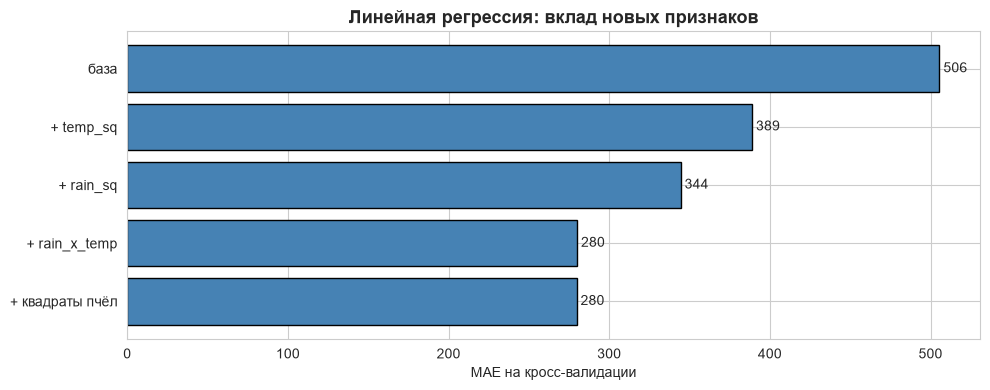

In [7]:
steps = [[], ["temp_sq"], ["temp_sq", "rain_sq"], ["temp_sq", "rain_sq", "rain_x_temp"],
         ["temp_sq", "rain_sq", "rain_x_temp", "osmia_sq", "andrena_sq"]]
rows = []
for s in steps:
    score = evaluate(LinearRegression(), FACTORS + s, data=fe)
    rows.append({"набор": "7 факторов" + "".join(f" + {f}" for f in s), "признаков": 7 + len(s), **score})
steps_table = pd.DataFrame(rows).set_index("набор")
display(steps_table.round(3))

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(range(len(steps_table)), steps_table["MAE"], color="steelblue", edgecolor="black")
ax.set_yticks(range(len(steps_table)))
ax.set_yticklabels(["база", "+ temp_sq", "+ rain_sq", "+ rain_x_temp", "+ квадраты пчёл"])
ax.invert_yaxis()
for i, v in enumerate(steps_table["MAE"]):
    ax.text(v, i, f" {v:.0f}", va="center")
ax.set_xlabel("MAE на кросс-валидации")
ax.set_title("Линейная регрессия: вклад новых признаков", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

Три подтверждённых признака вместе снижают ошибку линейной модели **примерно с 506 до 280 (почти вдвое)**, R² растёт с 0.79 до 0.93. Квадраты пчёл к этому ничего не добавляют — в итоговый набор их не берём.

In [8]:
NEW_FEATURES = ["temp_sq", "rain_sq", "rain_x_temp"]
FEATURES = FACTORS + NEW_FEATURES

hgb = HistGradientBoostingRegressor(random_state=RANDOM_STATE)
tree_cmp = pd.DataFrame({
    "7 факторов": evaluate(hgb, FACTORS, data=fe),
    "7 факторов + 3 новых": evaluate(hgb, FEATURES, data=fe),
}).T
print("Градиентный бустинг (деревья):")
tree_cmp.round(3)

Градиентный бустинг (деревья):


,MAE,R²
7 факторов,157.016,0.977
7 факторов + 3 новых,159.678,0.977


### 💡 Зачем признаки, если деревьям они не нужны
Бустингу новые признаки **не помогают**: деревья сами находят оптимумы и взаимодействия, разбивая данные на участки. Значит, наши признаки — это не «новая информация», а **готовое описание нелинейности** для моделей, которые сами её не находят.

Польза всё равно есть:
- линейная модель с ними почти вдвое точнее и остаётся **интерпретируемой**: по коэффициентам видно положение оптимума температуры и силу взаимодействия «дождь × жара»;
- гипотезы проверены и объясняют, **почему** деревья точнее линейной модели в `02_modeling.ipynb`.

---
# **3. Стратегия предобработки** 🧭

Каждое решение ниже следует из конкретного вывода EDA или этой тетрадки.

### 3.1 Пропуски
В данных **нет ни одного пропуска** (EDA, раздел 3.1) — симуляция выдаёт полную таблицу. Заполнение не нужно, сравнивать способы заполнения не на чем.
На будущее (полевые данные): в пайплайн стоит заложить `SimpleImputer` (медиана для плотностей пчёл — они скошены) и проверять его на той же схеме валидации.

### 3.2 Аномалии и лишние столбцы
- 18 строк особого блока (Row# 759–776) **исключаем** из обучения: условия, которых нет в сетке (EDA, раздел 3.3).
- Удаляем 5 дублирующих температур и `AverageRainingDays` (корреляция ≈ 1, раздел 3.4) — иначе у линейной модели неустойчивые коэффициенты.
- Удаляем `fruitset`, `fruitmass`, `seeds` — утечка цели (раздел 3.5).

### 3.3 Кодирование
Все признаки числовые, но у каждого всего 3–5 уровней. Значит, есть два разумных варианта, их сравниваем ниже:
- **числа + новые признаки** — сохраняют порядок уровней, признаков мало (10), коэффициенты читаются;
- **one-hot по уровням** — каждый уровень становится отдельным признаком; линейная модель сама получает любую форму зависимости, но признаков больше (26), и модель не умеет предсказывать для уровней, которых не было в обучении.

### 3.4 Масштабирование
Признаки в очень разных единицах: плотность пчёл 0.25–0.75, температура 58–79, `temp_sq` — тысячи. Ожидания:
- **деревьям** масштаб безразличен — они сравнивают значения с порогами;
- **обычной линейной регрессии** масштаб не меняет прогноз, но меняет величину коэффициентов;
- **Ridge и Lasso** штрафуют за величину коэффициентов, поэтому масштаб меняет сам результат.

Это проверяем в разделе 4.

In [9]:
cat_cols = FACTORS
onehot = make_pipeline(make_column_transformer((OneHotEncoder(handle_unknown="ignore"), cat_cols)),
                       LinearRegression())
n_onehot = sum(df_clean[c].nunique() for c in cat_cols)

enc_table = pd.DataFrame({
    "7 факторов как числа": {**evaluate(LinearRegression(), FACTORS, data=fe), "признаков": 7},
    "one-hot по уровням": {**evaluate(onehot, FACTORS, data=fe), "признаков": n_onehot},
    "числа + 3 новых признака": {**evaluate(LinearRegression(), FEATURES, data=fe), "признаков": len(FEATURES)},
}).T
enc_table.round(3)

,MAE,R²,признаков
7 факторов как числа,505.516,0.790,7.0
one-hot по уровням,319.939,0.913,26.0
числа + 3 новых признака,279.954,0.925,10.0


**Решение по кодированию:** оставляем **числа + 3 новых признака**. Они точнее one-hot при числе признаков в 2.5 раза меньше, сохраняют порядок уровней и дают коэффициенты, у которых есть физический смысл (оптимум температуры, сила взаимодействия). One-hot тоже сильно лучше исходных чисел — это ещё одно подтверждение, что связи нелинейные.

---
# **4. ★ Сравнение способов масштабирования** ⚖️

**Что сравниваем:** без масштабирования, `StandardScaler` (среднее 0, разброс 1), `MinMaxScaler` (в диапазон 0–1), `RobustScaler` (медиана и межквартильный размах — устойчив к выбросам).
**На каких моделях:** линейная регрессия, Ridge (L2-штраф за сумму квадратов коэффициентов), Lasso (L1-штраф за сумму модулей, умеет обнулять коэффициенты).
**Схема:** та же 5-кратная стратифицированная кросс-валидация, итоговые 10 признаков. Масштабирование стоит внутри `Pipeline`: параметры масштаба считаются только по обучающей части фолда — без утечки.

Сначала посмотрим, в каких единицах признаки, — от этого зависит всё остальное.

In [10]:
scale_info = fe[FEATURES].agg(["min", "max", "std"]).T
scale_info["IQR"] = fe[FEATURES].quantile(0.75) - fe[FEATURES].quantile(0.25)
scale_info.round(2)

,min,max,std,IQR
clonesize,12.50,37.50,7.03,12.50
honeybee,0.25,0.75,0.13,0.25
bumbles,0.25,0.38,0.06,0.13
andrena,0.25,0.75,0.16,0.25
osmia,0.25,0.75,0.15,0.25
AverageOfUpperTRange,58.20,79.00,7.75,14.30
RainingDays,1.00,34.00,12.08,23.00
temp_sq,3387.24,6241.00,1065.93,2054.91
rain_sq,1.00,1156.00,431.07,575.00
rain_x_temp,58.20,2686.00,847.94,1817.00


Плотности пчёл меняются в пределах 0.25–0.75, а `temp_sq` — в тысячах, разброс отличается **в десятки тысяч раз**. Заметим также: у `bumbles` межквартильный размах равен всему диапазону (0.13), поэтому для него `RobustScaler` и `MinMaxScaler` дают одинаковый масштаб.

## 4.1 Одинаковая сила штрафа

Берём одну и ту же `alpha` для всех способов масштабирования и смотрим, что происходит с ошибкой и с числом коэффициентов.

In [11]:
SCALERS = {"без масштабирования": None, "StandardScaler": StandardScaler(),
           "MinMaxScaler": MinMaxScaler(), "RobustScaler": RobustScaler()}

def build(scaler, model):
    return make_pipeline(scaler, model) if scaler is not None else make_pipeline(model)

rows = []
for alpha in [1, 10, 100]:
    for sname, scaler in SCALERS.items():
        ridge_mae = evaluate(build(scaler, Ridge(alpha=alpha)), FEATURES, data=fe)["MAE"]
        lasso = build(scaler, Lasso(alpha=alpha, max_iter=500_000))
        lasso_mae = evaluate(lasso, FEATURES, data=fe)["MAE"]
        coef = pd.Series(lasso.fit(fe[FEATURES], y)[-1].coef_, index=FEATURES)
        rows.append({"alpha": alpha, "масштабирование": sname,
                     "Ridge MAE": ridge_mae, "Lasso MAE": lasso_mae,
                     "Lasso: ненулевых коэф.": int((coef.abs() > 1e-8).sum()),
                     "Lasso: выброшены": ", ".join(coef.index[coef.abs() <= 1e-8]) or "—"})
fixed_table = pd.DataFrame(rows).set_index(["alpha", "масштабирование"])
fixed_table.round(1)

Ridge MAE  Lasso MAE  Lasso: ненулевых коэф.  \
alpha масштабирование                                                     
1     без масштабирования      291.9      279.1                       9   
      StandardScaler           352.6      282.7                      10   
      MinMaxScaler             437.8      303.0                      10   
      RobustScaler             390.7      288.1                      10   
10    без масштабирования      369.7      315.2                       9   
      StandardScaler           444.6      463.8                       8   
      MinMaxScaler             482.9      467.9                       7   
      RobustScaler             461.5      466.7                       7   
100   без масштабирования      493.5      556.4                       6   
      StandardScaler           484.5      502.7                       6   
      MinMaxScaler             653.2      672.1                       5   
      RobustScaler             539.7      562.4                       5   

                                                            Lasso: выброшены  
alpha масштабирование                                                         
1     без масштабирования                                           honeybee  
      StandardScaler                                                       —  
      MinMaxScaler                                                         —  
      RobustScaler                                                         —  
10    без масштабирования                                           honeybee  
      StandardScaler                          honeybee, AverageOfUpperTRange  
      MinMaxScaler               honeybee, AverageOfUpperTRange, RainingDays  
      RobustScaler               honeybee, AverageOfUpperTRange, RainingDays  
100   без масштабирования                  honeybee, bumbles, andrena, osmia  
      StandardScaler       honeybee, andrena, AverageOfUpperTRange, Raini...  
      MinMaxScaler         honeybee, andrena, AverageOfUpperTRange, Raini...  
      RobustScaler         honeybee, andrena, AverageOfUpperTRange, Raini...

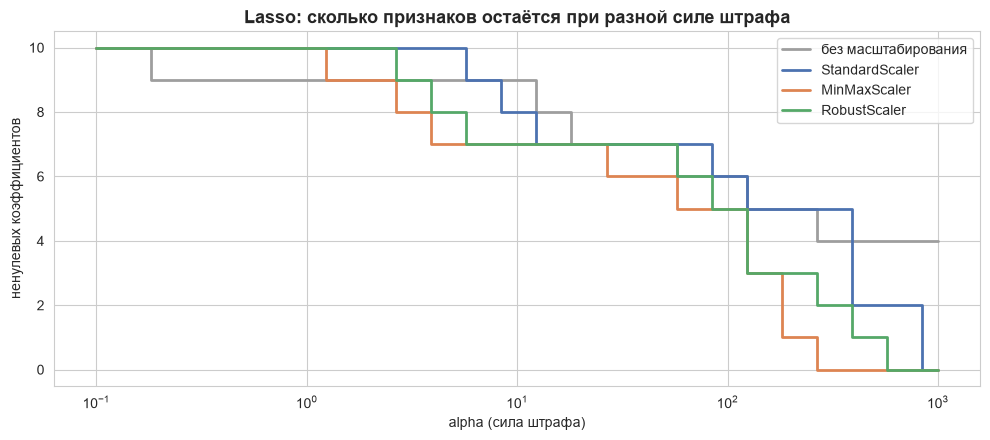

In [12]:
# Сколько признаков оставляет Lasso при разной силе штрафа
path_alphas = np.logspace(-1, 3, 25)
fig, ax = plt.subplots(figsize=(10, 4.5))
for (sname, scaler), color in zip(SCALERS.items(), ["#9E9E9E", "#4C72B0", "#DD8452", "#55A868"]):
    n_nonzero = []
    for a in path_alphas:
        coef = build(scaler, Lasso(alpha=a, max_iter=500_000)).fit(fe[FEATURES], y)[-1].coef_
        n_nonzero.append((np.abs(coef) > 1e-8).sum())
    ax.step(path_alphas, n_nonzero, where="mid", label=sname, color=color, linewidth=2)
ax.set_xscale("log")
ax.set_xlabel("alpha (сила штрафа)")
ax.set_ylabel("ненулевых коэффициентов")
ax.set_title("Lasso: сколько признаков остаётся при разной силе штрафа", fontsize=13, fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()

### 💡 Что видно при одинаковой `alpha`

- **Ошибка зависит от масштабирования.** При `alpha = 1` Ridge без масштабирования ошибается на ~290, а с `MinMaxScaler` — на ~440. Причина: штраф одинаковый, а «цена» коэффициента разная. После `MinMaxScaler` все признаки в диапазоне 0–1, коэффициенты температуры и `temp_sq` становятся огромными (десятки тысяч) — и штраф давит именно на них, хотя это самые важные признаки.
- **Состав признаков у Lasso зависит от масштабирования.** При `alpha = 100` без масштабирования Lasso выбрасывает **всех диких пчёл**. Они не бесполезны — их значения просто лежат в узком диапазоне 0.25–0.75, поэтому им нужны большие коэффициенты, а большие коэффициенты дорого стоят. Со `StandardScaler` пчёлы остаются, а выбрасываются `AverageOfUpperTRange` и `RainingDays` — их информацию уже несут `temp_sq` и `rain_x_temp`.
- **На графике** то же самое: при очень сильном штрафе без масштабирования остаются `clonesize`, `temp_sq`, `rain_sq`, `rain_x_temp` — признаки в больших единицах, которым хватает крошечных коэффициентов. С масштабированием все признаки в равных условиях, и при сильном штрафе обнуляется всё.
- **Вывод:** без масштабирования регуляризация штрафует признаки за **единицы измерения**, а не за бесполезность. Отбор признаков через Lasso имеет смысл только после масштабирования.

## 4.2 Сила штрафа подобрана для каждого способа

Одна `alpha` для разных масштабов — это разная по сути регуляризация. Честнее подобрать `alpha` для каждого способа отдельно (`RidgeCV`, `LassoCV`), причём **внутри** обучающей части каждого фолда — тест фолда в подборе не участвует.

In [13]:
ALPHAS = np.logspace(-4, 4, 33)
MODELS = {"LinearRegression": lambda: LinearRegression(),
          "Ridge": lambda: RidgeCV(alphas=ALPHAS),
          "Lasso": lambda: LassoCV(alphas=ALPHAS, max_iter=200_000, cv=5)}

rows, coefs = [], {}
for mname, make_model in MODELS.items():
    for sname, scaler in SCALERS.items():
        pipe = build(scaler, make_model())
        score = evaluate(pipe, FEATURES, data=fe)
        pipe.fit(fe[FEATURES], y)                 # обучаем на всех данных, чтобы посмотреть коэффициенты
        est = pipe[-1]
        coef = pd.Series(est.coef_, index=FEATURES)
        coefs[(mname, sname)] = coef
        rows.append({"модель": mname, "масштабирование": sname, **score,
                     "alpha": getattr(est, "alpha_", np.nan),
                     "ненулевых коэф.": int((coef.abs() > 1e-8).sum()),
                     "max |коэф.|": coef.abs().max(),
                     "min |коэф.|": coef.abs().min()})

scaling_table = pd.DataFrame(rows).set_index(["модель", "масштабирование"])
scaling_table.round({"MAE": 2, "R²": 4, "alpha": 4, "max |коэф.|": 1, "min |коэф.|": 2})

MAE      R²   alpha  ненулевых коэф.  \
модель           масштабирование                                                
LinearRegression без масштабирования  279.95  0.9253     NaN               10   
                 StandardScaler       279.95  0.9253     NaN               10   
                 MinMaxScaler         279.95  0.9253     NaN               10   
                 RobustScaler         279.95  0.9253     NaN               10   
Ridge            без масштабирования  279.93  0.9253  0.0100               10   
                 StandardScaler       279.94  0.9253  0.0018               10   
                 MinMaxScaler         279.95  0.9253  0.0002               10   
                 RobustScaler         279.95  0.9253  0.0003               10   
Lasso            без масштабирования  279.95  0.9253  0.0001               10   
                 StandardScaler       279.92  0.9253  0.0001               10   
                 MinMaxScaler         279.95  0.9253  0.0001               10   
                 RobustScaler         279.95  0.9253  0.0001               10   

                                      max |коэф.|  min |коэф.|  
модель           масштабирование                                
LinearRegression без масштабирования       5386.0         1.52  
                 StandardScaler            8691.5         7.00  
                 MinMaxScaler             23336.2        26.76  
                 RobustScaler             16442.9        13.38  
Ridge            без масштабирования       5364.2         1.52  
                 StandardScaler            8671.1         7.03  
                 MinMaxScaler             23296.8        26.86  
                 RobustScaler             16418.2        13.42  
Lasso            без масштабирования       5385.9         1.52  
                 StandardScaler            8691.4         7.00  
                 MinMaxScaler             23335.4        26.76  
                 RobustScaler             16442.5        13.38

При подобранной `alpha` **все 12 вариантов дают одинаковую ошибку** (MAE ≈ 279.9, R² 0.925), подобранная `alpha` крошечная, Lasso не обнуляет ни одного коэффициента. Это значит, что регуляризация здесь **не нужна**: 759 строк на 10 признаков, в симуляции нет шума — переобучаться линейной модели не на чем. Лучшая модель — по сути обычная линейная регрессия.

## 4.3 Как масштабирование меняет коэффициенты

Ниже коэффициенты линейной регрессии. Прогнозы у всех четырёх вариантов **одинаковые**, а коэффициенты — нет.

In [14]:
ols_coefs = pd.DataFrame({s: coefs[("LinearRegression", s)] for s in SCALERS})
ols_coefs.round(2)

,без масштабирования,StandardScaler,MinMaxScaler,RobustScaler
clonesize,-94.61,-664.64,-2365.17,-1182.58
honeybee,-53.53,-7.00,-26.76,-13.38
bumbles,5385.97,314.14,700.18,700.18
andrena,500.86,78.86,250.43,125.21
osmia,2099.02,318.91,1049.51,524.76
AverageOfUpperTRange,1121.93,8691.47,23336.17,16043.62
RainingDays,165.60,1998.59,5464.67,3808.71
temp_sq,-8.00,-8523.67,-22835.08,-16442.88
rain_sq,-1.52,-656.39,-1759.87,-876.12
rain_x_temp,-2.62,-2220.03,-6884.49,-4760.30


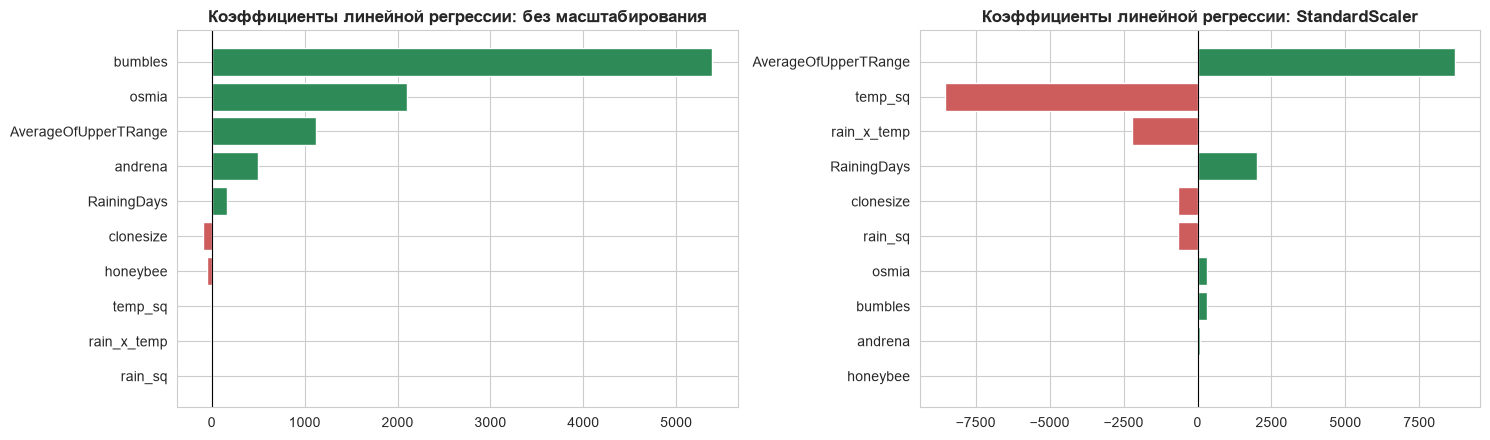

In [15]:
std_coef = coefs[("LinearRegression", "StandardScaler")]
raw_coef = coefs[("LinearRegression", "без масштабирования")]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, c, title in [(axes[0], raw_coef, "без масштабирования"),
                     (axes[1], std_coef, "StandardScaler")]:
    order = c.abs().sort_values().index
    ax.barh(order, c[order], color=["indianred" if v < 0 else "seagreen" for v in c[order]])
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"Коэффициенты линейной регрессии: {title}", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

- **Без масштабирования** самый большой коэффициент у `bumbles` (≈ 5400), а у `temp_sq` — всего −8. Но это не важность: +1 шмель на м² — шаг больше всего диапазона (0.25–0.38), а +1 к `temp_sq` — ничтожная доля от тысяч. Коэффициент — эффект **одной единицы**, а единицы несравнимы.
- **После `StandardScaler`** коэффициент — эффект изменения на **одно стандартное отклонение**, и их можно сравнивать. Порядок меняется: на первых местах температура и `temp_sq` (≈ ±8600 — большие и противоположные по знаку, вместе дают параболу), затем `rain_x_temp` и дожди, потом клон и `rain_sq`, осмии и шмели. `honeybee` — около нуля (как и в EDA).
- `MinMaxScaler` и `RobustScaler` дают те же выводы, но величины коэффициентов ещё больше (до 23 000 и 16 000) — шаг «весь диапазон» и «межквартильный размах» крупнее одного стандартного отклонения.

Коэффициенты исходной модели тоже полезны — в физических единицах по ним можно найти оптимум температуры:

In [16]:
# вклад температуры = b1*T + b2*T² + b3*Rain*T → вершина параболы T* = -(b1 + b3*Rain) / (2*b2)
b1, b2, b3 = raw_coef["AverageOfUpperTRange"], raw_coef["temp_sq"], raw_coef["rain_x_temp"]
for rain in sorted(df_clean["RainingDays"].unique()):
    print(f"Дождливых дней {rain:>4.0f}: оптимальная температура по модели ≈ {-(b1 + b3 * rain) / (2 * b2):.1f} °F")

Дождливых дней    1: оптимальная температура по модели ≈ 69.9 °F
Дождливых дней   16: оптимальная температура по модели ≈ 67.5 °F
Дождливых дней   24: оптимальная температура по модели ≈ 66.2 °F
Дождливых дней   34: оптимальная температура по модели ≈ 64.5 °F


Чем дождливее сезон, тем ниже оптимальная температура (с 70 до 64.5 °F) — это и есть взаимодействие «дождь × жара» из гипотезы 3, выраженное в градусах.

### ✅ Решение по масштабированию

| Модель | Решение | Почему |
|---|---|---|
| Линейная регрессия | **`StandardScaler`** | метрика та же при любом способе, но коэффициенты в одной шкале — их можно сравнивать и объяснять |
| Ridge / Lasso | **`StandardScaler`**, `alpha` подбирать | без масштабирования штраф зависит от единиц измерения: Lasso выбрасывает пчёл только потому, что их значения маленькие (раздел 4.1) |
| Деревья (бустинг, лес) | **без масштабирования** | разбиения по порогам от масштаба не зависят |

Почему не `MinMaxScaler` и не `RobustScaler`: выбросов в основной сетке нет (особый блок исключён) — устойчивость `RobustScaler` не нужна; у дискретных признаков с 3–5 уровнями межквартильный размах грубый (у `bumbles` он равен всему диапазону). При одинаковой `alpha` оба варианта давали ошибку хуже, чем `StandardScaler`.

---
# 📝 **Итоги: что передаём в модель**

| Шаг | Решение | Основание |
|---|---|---|
| Задача | регрессия, цель `yield`, объект — сценарий симуляции | раздел 1 |
| Валидация | 5-кратная CV, стратификация по `clonesize` | редкий клон 37.5 |
| Пропуски | не заполняем — их нет | EDA, 3.1 |
| Строки | без особого блока Row# 759–776 | EDA, 3.3 |
| Признаки | 7 факторов + `temp_sq`, `rain_sq`, `rain_x_temp` | гипотезы 1–3 подтверждены (раздел 2) |
| Отклонено | квадраты пчёл, `wild_bees`, `bees_per_clone` | не уменьшают ошибку (раздел 2) |
| Кодирование | числа, без one-hot | точнее one-hot при 10 признаках вместо 26 (раздел 3.3) |
| Масштабирование | `StandardScaler` для линейных моделей, без масштабирования для деревьев | раздел 4 |
| Регуляризация | не нужна: подобранная `alpha` ≈ 0, ошибка как у обычной регрессии | раздел 4.2 |

**Главный результат:** признаки, построенные по гипотезам из EDA, почти вдвое снижают ошибку линейной модели (MAE ≈ 506 → 280, R² 0.79 → 0.93). Для деревьев они не нужны — те находят ту же нелинейность сами.